<a href="https://colab.research.google.com/github/udaybhaskar29/House-Price-Prediction/blob/main/feature_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns',None)

In [3]:
df = pd.read_csv('gurgaon_properties_missing_value_imputation.csv')

In [4]:
df.shape

(3554, 18)

In [5]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,signature global park 4,sector 36,0.82,7586.0,3,2,2,2.0,New Property,850.0,0,0,0,0,0,0,8
1,flat,smart world gems,sector 89,0.95,8597.0,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,0,38
2,flat,breez global hill view,sohna road,0.32,5470.0,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,0,49
3,flat,bestech park view sanskruti,sector 92,1.60,8020.0,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,1,174
4,flat,suncity avenue,sector 102,0.48,9023.0,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,0,159


In [6]:
train_df = df.drop(columns=['society','price_per_sqft'])

In [7]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,sector 36,0.82,3,2,2,2.0,New Property,850.0,0,0,0,0,0,0,8
1,flat,sector 89,0.95,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,0,38
2,flat,sohna road,0.32,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,0,49
3,flat,sector 92,1.60,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,1,174
4,flat,sector 102,0.48,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,0,159


### luxury score

<Axes: xlabel='luxury_score'>

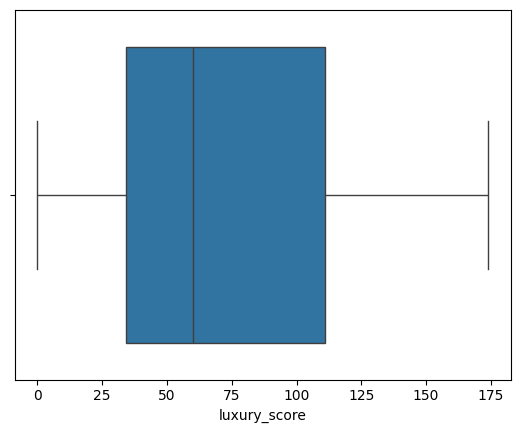

In [8]:
sns.boxplot(x = df['luxury_score'])

In [9]:
def categorize_luxury(score):
  if 0 <= score < 50:
    return 'Low'
  elif 50 <= score < 150:
    return 'Medium'
  elif 150 <= score < 175:
    return 'High'
  else:
    return 'Undefined' # score outside the defined bins

In [10]:
train_df['luxury_category'] = train_df['luxury_score'].apply(categorize_luxury)

In [11]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category
0,flat,sector 36,0.82,3,2,2,2.0,New Property,850.0,0,0,0,0,0,0,8,Low
1,flat,sector 89,0.95,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,0,38,Low
2,flat,sohna road,0.32,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,0,49,Low
3,flat,sector 92,1.60,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,1,174,High
4,flat,sector 102,0.48,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,0,159,High


### FloorNum

<Axes: xlabel='floorNum'>

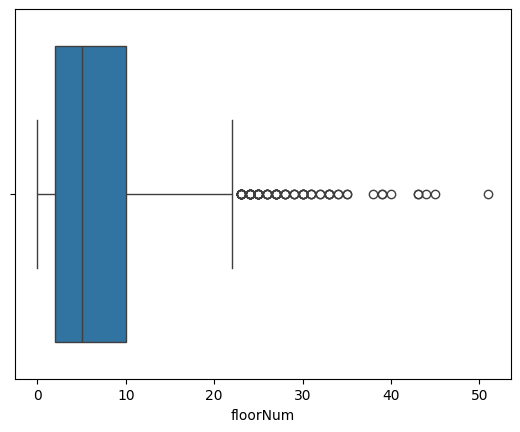

In [12]:
sns.boxplot(x = df['floorNum'])

In [13]:
def categorize_floor(floor):
  if 0 <= floor < 2:
    return 'Low Floor'
  if 3 <= floor < 10:
    return 'Low Floor'
  if 11 <= floor < 51:
    return 'Low Floor'
  else:
    return None # undefined or any floor outside the defined bins

In [14]:
train_df['floor_category'] = train_df['floorNum'].apply(categorize_floor)

In [15]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category,floor_category
0,flat,sector 36,0.82,3,2,2,2.0,New Property,850.0,0,0,0,0,0,0,8,Low,None
1,flat,sector 89,0.95,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,0,38,Low,Low Floor
2,flat,sohna road,0.32,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,0,49,Low,Low Floor
3,flat,sector 92,1.60,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,1,174,High,None
4,flat,sector 102,0.48,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,0,159,High,Low Floor


In [16]:
train_df.drop(columns=['floorNum','luxury_score'],inplace = True)

In [17]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,flat,sector 36,0.82,3,2,2,New Property,850.0,0,0,0,0,0,0,Low,None
1,flat,sector 89,0.95,2,2,2,New Property,1226.0,1,1,0,0,0,0,Low,Low Floor
2,flat,sohna road,0.32,2,2,1,New Property,1000.0,0,0,0,0,0,0,Low,Low Floor
3,flat,sector 92,1.60,3,4,3+,Relatively New,1615.0,0,1,0,0,1,1,High,None
4,flat,sector 102,0.48,2,2,1,Relatively New,582.0,0,0,1,0,0,0,High,Low Floor


In [18]:
from sklearn.preprocessing import OrdinalEncoder

# Create a copy of the original data for label encoding
data_label_encoded = train_df.copy()

categorical_cols = train_df.select_dtypes(include=['object']).columns

# Apply label encoding to categorical columns
for col in categorical_cols:
    oe = OrdinalEncoder()
    data_label_encoded[col] = oe.fit_transform(data_label_encoded[[col]])
    print(oe.categories_)

# Splitting the dataset into training and testing sets
X_label = data_label_encoded.drop('price', axis=1)
y_label = data_label_encoded['price']


[array(['flat', 'house'], dtype=object)]
[array(['dwarka expressway', 'gwal pahari', 'manesar', 'sector 1',
       'sector 10', 'sector 102', 'sector 103', 'sector 104',
       'sector 105', 'sector 106', 'sector 107', 'sector 108',
       'sector 109', 'sector 11', 'sector 110', 'sector 111',
       'sector 112', 'sector 113', 'sector 12', 'sector 13', 'sector 14',
       'sector 15', 'sector 17', 'sector 2', 'sector 21', 'sector 22',
       'sector 23', 'sector 24', 'sector 25', 'sector 26', 'sector 27',
       'sector 28', 'sector 3', 'sector 30', 'sector 31', 'sector 33',
       'sector 36', 'sector 37', 'sector 37d', 'sector 38', 'sector 39',
       'sector 4', 'sector 40', 'sector 41', 'sector 43', 'sector 45',
       'sector 46', 'sector 47', 'sector 48', 'sector 49', 'sector 5',
       'sector 50', 'sector 51', 'sector 52', 'sector 53', 'sector 54',
       'sector 55', 'sector 56', 'sector 57', 'sector 58', 'sector 59',
       'sector 6', 'sector 60', 'sector 61', 'sector 62', 

In [19]:
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,0.0,36.0,3,2,2.0,1.0,850.0,0,0,0,0,0,0,1.0,1.0
1,0.0,95.0,2,2,2.0,1.0,1226.0,1,1,0,0,0,0,1.0,0.0
2,0.0,103.0,2,2,1.0,1.0,1000.0,0,0,0,0,0,0,1.0,0.0
3,0.0,99.0,3,4,4.0,3.0,1615.0,0,1,0,0,1,1,0.0,1.0
4,0.0,5.0,2,2,1.0,3.0,582.0,0,0,1,0,0,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3549,0.0,90.0,2,2,1.0,3.0,532.0,0,0,0,0,0,0,2.0,0.0
3550,1.0,12.0,5,5,4.0,3.0,6228.0,1,1,1,1,0,0,0.0,1.0
3551,0.0,23.0,1,1,1.0,0.0,665.0,0,0,0,0,0,1,2.0,0.0
3552,1.0,44.0,5,6,3.0,0.0,5490.0,1,1,1,1,0,0,2.0,0.0


In [20]:
y_label

,price
0,0.82
1,0.95
2,0.32
3,1.60
4,0.48
...,...
3549,0.37
3550,6.00
3551,0.60
3552,15.50


### Technique 1: Correlation Analysis

<Axes: >

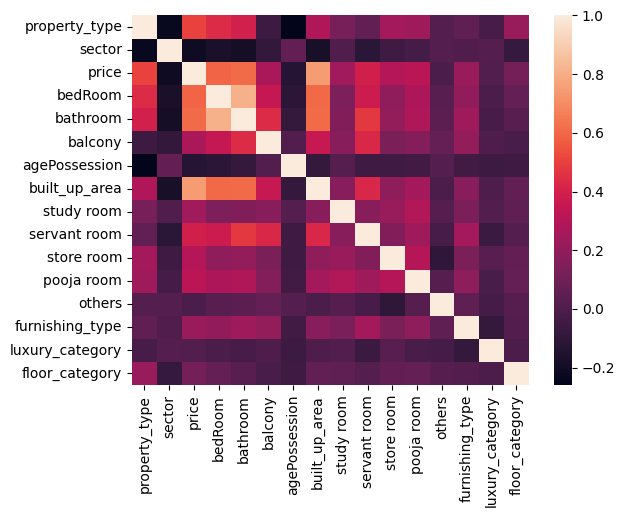

In [21]:
sns.heatmap(data_label_encoded.corr(numeric_only=True))

In [22]:
fi_df1 = data_label_encoded.corr()[['price']].drop('price').reset_index().rename(columns={'index':'feature','price':'corr_coeff'})
fi_df1

,feature,corr_coeff
0,property_type,0.503728
1,sector,-0.212084
2,bedRoom,0.591289
3,bathroom,0.609777
4,balcony,0.269637
5,agePossession,-0.134171
6,built_up_area,0.748574
7,study room,0.242955
8,servant room,0.391930
9,store room,0.305677


### Technique2 : Random Forest Feature Importance

In [23]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest Regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators = 100,random_state=42)
rf_label.fit(X_label,y_label)

# Extract feature importance scores for label encoded data
fi_df2 = pd.DataFrame({
    'feature': X_label.columns,
    'rf_importance': rf_label.feature_importances_
}).sort_values(by='rf_importance', ascending=False)

fi_df2

,feature,rf_importance
6,built_up_area,0.650804
1,sector,0.102952
0,property_type,0.100352
3,bathroom,0.026488
2,bedRoom,0.023689
8,servant room,0.019543
5,agePossession,0.014509
4,balcony,0.012863
12,furnishing_type,0.010566
7,study room,0.008947


### Technique3 : Gradient Boosting feature importances


In [24]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Random Forest regressor on label encoded data
gb_label = GradientBoostingRegressor()
gb_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df3 = pd.DataFrame({
    'feature': X_label.columns,
    'gb_importance': gb_label.feature_importances_
}).sort_values(by='gb_importance', ascending=False)

fi_df3


,feature,gb_importance
6,built_up_area,0.678753
1,sector,0.103347
0,property_type,0.098364
2,bedRoom,0.037054
3,bathroom,0.035716
8,servant room,0.022940
9,store room,0.010211
5,agePossession,0.004157
7,study room,0.003156
12,furnishing_type,0.002528


### Technique 4 - Permutation Importance


In [25]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(X_label, y_label, test_size=0.2, random_state=42)

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_train_label, y_train_label)

# Calculate Permutation Importance
perm_importance = permutation_importance(rf_label, X_test_label, y_test_label, n_repeats=30, random_state=42)

# Organize results into a DataFrame
fi_df4 = pd.DataFrame({
    'feature': X_label.columns,
    'permutation_importance': perm_importance.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

fi_df4

,feature,permutation_importance
6,built_up_area,0.729382
0,property_type,0.197698
1,sector,0.176364
2,bedRoom,0.022376
3,bathroom,0.021145
8,servant room,0.020177
5,agePossession,0.006067
13,luxury_category,0.000661
14,floor_category,0.000359
9,store room,0.000356


### Technique 5 - LASSO

In [26]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_label)

# Train a LASSO regression model
# We'll use a relatively small value for alpha (the regularization strength) for demonstration purposes
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y_label)

# Extract coefficients
fi_df5 = pd.DataFrame({
    'feature': X_label.columns,
    'lasso_coeff': lasso.coef_
}).sort_values(by='lasso_coeff', ascending=False)

fi_df5

# not very much reliable because the data is ordinal encoded.(not one hot encoded)
# ordinal encoding not very good for linear model

,feature,lasso_coeff
6,built_up_area,1.509983
0,property_type,0.707999
3,bathroom,0.278118
9,store room,0.199348
7,study room,0.171229
12,furnishing_type,0.164029
8,servant room,0.159756
10,pooja room,0.073536
13,luxury_category,0.055212
14,floor_category,0.023817


### Technique 6 - RFE

In [27]:
from sklearn.feature_selection import RFE

# Initialize the base estimator
estimator = RandomForestRegressor()

# Apply RFE on the label-encoded and standardized training data
selector_label = RFE(estimator, n_features_to_select=X_label.shape[1], step=1)
selector_label = selector_label.fit(X_label, y_label)

# Get the selected features based on RFE
selected_features = X_label.columns[selector_label.support_]

# Extract the coefficients for the selected features from the underlying linear regression model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
fi_df6 = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

fi_df6

,feature,rfe_score
6,built_up_area,0.647583
1,sector,0.107068
0,property_type,0.100490
2,bedRoom,0.026787
3,bathroom,0.024623
8,servant room,0.019114
5,agePossession,0.014535
4,balcony,0.011840
7,study room,0.010257
12,furnishing_type,0.010005


### Technique 7 - Linear Regression Weights

In [28]:
from sklearn.linear_model import LinearRegression
# Train a linear regression model on the label-encoded and standardized training data
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y_label)

# Extract coefficients
fi_df7 = pd.DataFrame({
    'feature': X_label.columns,
    'reg_coeffs': lin_reg.coef_
}).sort_values(by='reg_coeffs', ascending=False)

fi_df7
# not very much reliable
# tree based model are more reliable

,feature,reg_coeffs
6,built_up_area,1.513285
0,property_type,0.704335
3,bathroom,0.285079
9,store room,0.203355
7,study room,0.178767
12,furnishing_type,0.173190
8,servant room,0.168562
10,pooja room,0.076890
13,luxury_category,0.066395
14,floor_category,0.031864


### Technique 8 - SHAP

In [29]:
!pip install shap

In [30]:
import shap

# Compute SHAP values using the trained Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_label, y_label)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_label)

# Summing the absolute SHAP values across all samples to get an overall measure of feature importance
shap_sum = np.abs(shap_values).mean(axis=0)

shap_values

array([[-1.80724714e-01,  1.49886170e-01, -3.11976255e-02, ...,
        -1.28034211e-02, -3.61376004e-03,  1.37548379e-02],
       [-1.94784044e-01, -3.99717279e-01, -4.67420647e-02, ...,
        -1.17816132e-02, -3.74574670e-03, -1.87297740e-04],
       [-1.76254403e-01, -4.09877342e-01, -4.77604657e-02, ...,
        -1.35120376e-02, -1.36702503e-02, -3.16428817e-03],
       ...,
       [-1.79046493e-01,  7.35045616e-02, -7.76680028e-03, ...,
         5.77071611e-03,  1.24109210e-02, -4.17060189e-03],
       [ 1.58130798e+00,  9.82240147e-01,  3.81383080e-01, ...,
         1.00809560e-01,  2.57176010e-02, -1.59555775e-02],
       [-3.14774872e-01,  7.25099440e-02, -2.17988915e-02, ...,
         2.54024812e-03, -7.81935787e-03, -4.47786244e-03]],
      shape=(3554, 15))

In [31]:
fi_df8 = pd.DataFrame({
    'feature': X_label.columns,
    'SHAP_score': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_score', ascending=False)

fi_df8

,feature,SHAP_score
6,built_up_area,1.255676
0,property_type,0.467393
1,sector,0.384455
3,bathroom,0.115719
8,servant room,0.096358
2,bedRoom,0.050134
4,balcony,0.040921
12,furnishing_type,0.028356
5,agePossession,0.027838
7,study room,0.020483


In [32]:
final_fi_df = fi_df1.merge(fi_df2,on='feature').merge(fi_df3,on='feature').merge(fi_df4,on='feature').merge(fi_df5,on='feature').merge(fi_df6,on='feature').merge(fi_df7,on='feature').merge(fi_df8,on='feature').set_index('feature')

In [33]:
final_fi_df

,corr_coeff,rf_importance,gb_importance,permutation_importance,lasso_coeff,rfe_score,reg_coeffs,SHAP_score
feature,,,,,,,,
property_type,0.503728,0.100352,0.098364,0.197698,0.707999,0.100490,0.704335,0.467393
sector,-0.212084,0.102952,0.103347,0.176364,-0.068687,0.107068,-0.077299,0.384455
bedRoom,0.591289,0.023689,0.037054,0.022376,0.013401,0.026787,0.015843,0.050134
bathroom,0.609777,0.026488,0.035716,0.021145,0.278118,0.024623,0.285079,0.115719
balcony,0.269637,0.012863,0.002065,-0.001643,-0.043889,0.011840,-0.067225,0.040921
agePossession,-0.134171,0.014509,0.004157,0.006067,-0.000000,0.014535,-0.001815,0.027838
built_up_area,0.748574,0.650804,0.678753,0.729382,1.509983,0.647583,1.513285,1.255676
study room,0.242955,0.008947,0.003156,-0.020027,0.171229,0.010257,0.178767,0.020483
servant room,0.391930,0.019543,0.022940,0.020177,0.159756,0.019114,0.168562,0.096358


In [34]:
# normalize the score
final_fi_df = final_fi_df.divide(final_fi_df.sum(axis=0), axis=1)

In [35]:
final_fi_df[['rf_importance','gb_importance','permutation_importance','rfe_score','SHAP_score']].mean(axis=1).sort_values(ascending=False)

,0
feature,
built_up_area,0.621426
property_type,0.131058
sector,0.123657
bathroom,0.030136
bedRoom,0.025349
servant room,0.023403
agePossession,0.009884
balcony,0.008275
store room,0.006296


In [36]:
# to drop pooja room, study room, others
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,0.0,36.0,3,2,2.0,1.0,850.0,0,0,0,0,0,0,1.0,1.0
1,0.0,95.0,2,2,2.0,1.0,1226.0,1,1,0,0,0,0,1.0,0.0
2,0.0,103.0,2,2,1.0,1.0,1000.0,0,0,0,0,0,0,1.0,0.0
3,0.0,99.0,3,4,4.0,3.0,1615.0,0,1,0,0,1,1,0.0,1.0
4,0.0,5.0,2,2,1.0,3.0,582.0,0,0,1,0,0,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3549,0.0,90.0,2,2,1.0,3.0,532.0,0,0,0,0,0,0,2.0,0.0
3550,1.0,12.0,5,5,4.0,3.0,6228.0,1,1,1,1,0,0,0.0,1.0
3551,0.0,23.0,1,1,1.0,0.0,665.0,0,0,0,0,0,1,2.0,0.0
3552,1.0,44.0,5,6,3.0,0.0,5490.0,1,1,1,1,0,0,2.0,0.0


In [37]:
# with all the cols
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label, y_label, cv=5, scoring='r2')

In [38]:
scores.mean()

np.float64(0.8197937136733155)

In [39]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['pooja room', 'study room', 'others']), y_label, cv=5, scoring='r2')


In [40]:
scores.mean()

np.float64(0.8187110588127995)

In [41]:
export_df = X_label.drop(columns=['pooja room', 'study room', 'others'])
export_df['price'] = y_label

In [42]:
export_df.to_csv('gurgaon_properties_post_feature_selection.csv', index=False)

In [43]:
export_df

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,servant room,store room,furnishing_type,luxury_category,floor_category,price
0,0.0,36.0,3,2,2.0,1.0,850.0,0,0,0,1.0,1.0,0.82
1,0.0,95.0,2,2,2.0,1.0,1226.0,1,0,0,1.0,0.0,0.95
2,0.0,103.0,2,2,1.0,1.0,1000.0,0,0,0,1.0,0.0,0.32
3,0.0,99.0,3,4,4.0,3.0,1615.0,1,0,1,0.0,1.0,1.60
4,0.0,5.0,2,2,1.0,3.0,582.0,0,1,0,0.0,0.0,0.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3549,0.0,90.0,2,2,1.0,3.0,532.0,0,0,0,2.0,0.0,0.37
3550,1.0,12.0,5,5,4.0,3.0,6228.0,1,1,0,0.0,1.0,6.00
3551,0.0,23.0,1,1,1.0,0.0,665.0,0,0,1,2.0,0.0,0.60
3552,1.0,44.0,5,6,3.0,0.0,5490.0,1,1,0,2.0,0.0,15.50
